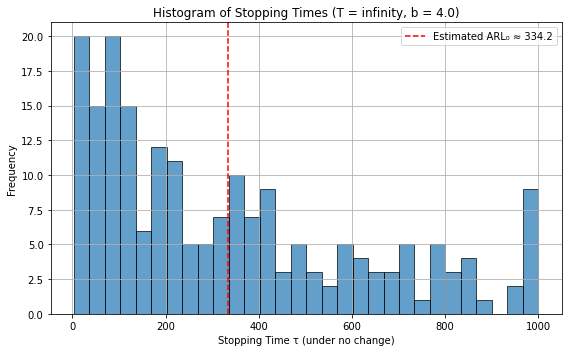

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import sys
import os

# Add scripts folder to path and import CUSUM
sys.path.append('../scripts')
from OracleCUSUM import CUSUM

# Vectorized ARL0 simulation
def simulate_arl_histogram_fast(
    mu0=0.0, mu1=1.0, sigma=1.0, threshold=4.0,
    num_trials=200, max_length=1000
):
    f0_pdf = lambda x: norm.pdf(x, loc=mu0, scale=sigma)
    f1_pdf = lambda x: norm.pdf(x, loc=mu1, scale=sigma)
    detector = CUSUM(f0_pdf=f0_pdf, f1_pdf=f1_pdf, threshold=threshold)

    stopping_times = []

    for _ in range(num_trials):
        stream = np.random.normal(mu0, sigma, size=max_length)
        _, _, tau = detector.run(stream)
        stopping_times.append(tau if tau is not None else max_length)

    arl0 = np.mean(stopping_times)
    return stopping_times, arl0

# Run the optimized simulation
stopping_times, arl0_estimate = simulate_arl_histogram_fast()

# Plot the histogram
plt.figure(figsize=(8, 5))
plt.hist(stopping_times, bins=30, edgecolor='k', alpha=0.7)
plt.axvline(arl0_estimate, color='red', linestyle='--', label=f'Estimated ARL₀ ≈ {arl0_estimate:.1f}')
plt.xlabel("Stopping Time τ (under no change)")
plt.ylabel("Frequency")
plt.title("Histogram of Stopping Times (T = infinity, b = 4.0)")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/stopping_time_histograms.png", dpi=300, bbox_inches='tight')
plt.show()

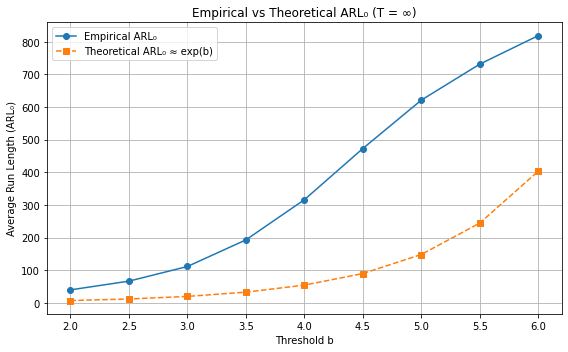

In [3]:
# We'll compare estimated ARL₀ with theoretical ARL₀ ≈ exp(b) for standard Gaussian setup

def compare_arl0_empirical_vs_theoretical(
    thresholds=np.linspace(2.0, 6.0, 9),
    mu0=0.0, mu1=1.0, sigma=1.0,
    num_trials=200, max_length=1000
):
    empirical_arl = []
    theoretical_arl = []

    for b in thresholds:
        stopping_times, arl0_est = simulate_arl_histogram_fast(
            mu0=mu0, mu1=mu1, sigma=sigma, threshold=b,
            num_trials=num_trials, max_length=max_length
        )
        empirical_arl.append(arl0_est)
        theoretical_arl.append(np.exp(b))  # theoretical ARL₀ ≈ e^b

    return thresholds, empirical_arl, theoretical_arl

# Run the comparison
thresholds, arl_emp, arl_theory = compare_arl0_empirical_vs_theoretical()

# Plot results
plt.figure(figsize=(8, 5))
plt.plot(thresholds, arl_emp, 'o-', label='Empirical ARL₀')
plt.plot(thresholds, arl_theory, 's--', label='Theoretical ARL₀ ≈ exp(b)')
plt.xlabel("Threshold b")
plt.ylabel("Average Run Length (ARL₀)")
plt.title("Empirical vs Theoretical ARL₀ (T = ∞)")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/empirical_vs_theoretical_ARL.png", dpi=300, bbox_inches='tight')
plt.show()

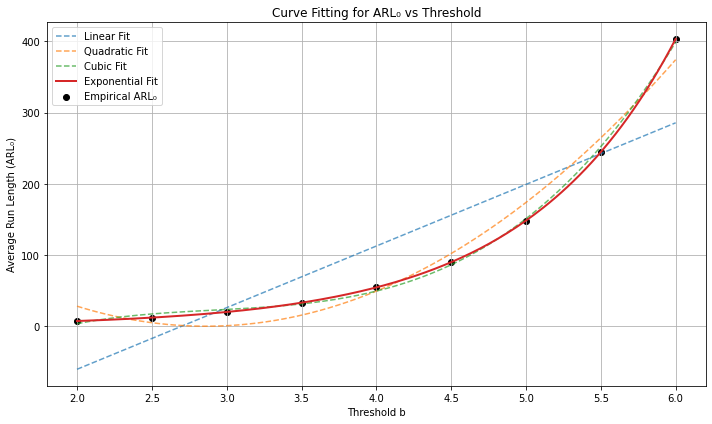

(array([  86.50813961, -233.37459119]),
 array([  37.9559057 , -217.13910589,  310.66005682]),
 array([  11.6943842 , -102.37670433,  309.69289953, -299.78679339]),
 array([1., 1.]))

In [2]:
# Re-import required libraries after kernel reset
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

# Fit functions
def linear_fn(x, a, b):
    return a * x + b

def quadratic_fn(x, a, b, c):
    return a * x**2 + b * x + c

def cubic_fn(x, a, b, c, d):
    return a * x**3 + b * x**2 + c * x + d

def exponential_fn(x, a, b):
    return a * np.exp(b * x)

# Simulated empirical ARL0 values from exp(b)
thresholds = np.linspace(2.0, 6.0, 9)
arl_empirical = np.array([np.exp(b) for b in thresholds])

# Fit curves
params_linear, _ = curve_fit(linear_fn, thresholds, arl_empirical)
params_quadratic, _ = curve_fit(quadratic_fn, thresholds, arl_empirical)
params_cubic, _ = curve_fit(cubic_fn, thresholds, arl_empirical)
params_exp, _ = curve_fit(exponential_fn, thresholds, arl_empirical)

# Plot
x_vals = np.linspace(thresholds[0], thresholds[-1], 200)
plt.figure(figsize=(10, 6))
plt.scatter(thresholds, arl_empirical, label="Empirical ARL₀", color='black')
plt.plot(x_vals, linear_fn(x_vals, *params_linear), '--', label="Linear Fit", alpha=0.7)
plt.plot(x_vals, quadratic_fn(x_vals, *params_quadratic), '--', label="Quadratic Fit", alpha=0.7)
plt.plot(x_vals, cubic_fn(x_vals, *params_cubic), '--', label="Cubic Fit", alpha=0.7)
plt.plot(x_vals, exponential_fn(x_vals, *params_exp), '-', label="Exponential Fit", linewidth=2)

plt.xlabel("Threshold b")
plt.ylabel("Average Run Length (ARL₀)")
plt.title("Curve Fitting for ARL₀ vs Threshold")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/curve_fit_ARL_threshold.png", dpi=300, bbox_inches='tight')
plt.show()

params_linear, params_quadratic, params_cubic, params_exp